# Bird Occurrence: Target Understanding, EDA and Preprocessing
**Research:** J26-IT-359 | **Dataset:** `data/processed/occurrence/targets_v1/occurrence_training_dataset.csv`

One row represents one **survey checklist × target species**. The verified dataset includes
24 endemic species and a binary Y column, `target_occurrence`: **1 = detected**,
**0 = not detected on an eligible complete checklist**. Zero does not confirm biological absence.

Run the cells from top to bottom in VS Code or Jupyter. The species and Y graphs are in
separate notebook cells, including graphs grouped by the geographic `cell_id`.
No imputation, encoding or scaling is fitted until you define training folds.

This sampling frame comes from the original selected-species observation dataset;
the targets describe detection within those surveys, not national occupancy.
See `data/processed/occurrence/targets_v1/README.md` for the labelling method.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Locate the project from the notebook working directory or any parent directory.
DATA_RELATIVE_PATH = Path('data/processed/occurrence/targets_v1/occurrence_training_dataset.csv')
PROJECT_ROOT = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / DATA_RELATIVE_PATH).is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f'Cannot find {DATA_RELATIVE_PATH}. Open this notebook from the occurrence_prediction component.'
    )
DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
OUTPUT = DATA_PATH.parent / 'preprocessing'
OUTPUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
required = {'checklist_id', 'survey_group_id', 'scientific_name', 'cell_id',
            'target_occurrence', 'survey_distance_km', 'hours_of_day', 'number_observers'}
if required - set(df.columns):
    raise ValueError(f'Missing required columns: {sorted(required - set(df.columns))}')
if df['target_occurrence'].isna().any() or not df['target_occurrence'].isin([0, 1]).all():
    raise ValueError('The training table must contain only verified binary Y values (0 or 1).')
df['target_occurrence'] = df['target_occurrence'].astype('int8')
survey_df = df.drop_duplicates('checklist_id').copy()
print('Dataset:', DATA_PATH)
print('Shape:', df.shape, '| Species:', df['scientific_name'].nunique())
print('Independent surveys:', survey_df['survey_group_id'].nunique())
print('Outputs created when you run this notebook:', OUTPUT)
display(df.head())

ModuleNotFoundError: No module named 'pandas'

## 1. Data understanding
The prediction unit is a **checklist–species pair**. A checklist appears once for each target
species, including species not detected there. `target_occurrence` is Y; `scientific_name`
identifies which species is being predicted. `all_species_reported` is checklist completeness,
not Y. Survey identifiers and `cell_id` are retained for grouping and validation.
The labelling release already selects one eligible representative per shared survey group.

In [ ]:
print('Rows:', len(df), '| Columns:', len(df.columns))
print('Column names:')
print(df.columns.tolist())
print('Data types:')
print(df.dtypes)
print('Summary of numeric columns:')
display(df.describe().T)
print('Summary of categorical columns:')
display(df.describe(include='object').T)
print('\nSpecies:', df['scientific_name'].nunique())
print('Checklists:', df['checklist_id'].nunique())
print('Geographic cells:', df['cell_id'].nunique())
print('Years:', sorted(df['year'].unique()))
print('Y counts:', df['target_occurrence'].value_counts().sort_index().to_dict())

Rows: 505608 | Columns: 24
Column names:
['checklist_id', 'survey_group_id', 'scientific_name', 'observation_date', 'year', 'month', 'cell_id', 'latitude', 'longitude', 'temperature_mean_c', 'rainfall_mm', 'elevation_m', 'ndvi', 'land_cover', 'duration_minutes', 'effort_distance_km', 'survey_distance_km', 'protocol', 'all_species_reported', 'hours_of_day', 'number_observers', 'effort_speed_kmph', 'target_occurrence', 'label_status']
Data types:
checklist_id             object
survey_group_id          object
scientific_name          object
observation_date         object
year                      int64
month                     int64
cell_id                  object
latitude                float64
longitude               float64
temperature_mean_c      float64
rainfall_mm             float64
elevation_m             float64
ndvi                    float64
land_cover               object
duration_minutes        float64
effort_distance_km      float64
survey_distance_km      float64
protoco

,count,mean,std,min,25%,50%,75%,max
year,505608.0,2020.699388,2.178569,2010.000000,2020.000000,2021.000000,2022.000000,2023.000000
month,505608.0,5.959890,3.633332,1.000000,3.000000,5.000000,9.000000,12.000000
latitude,505608.0,6.784404,0.585107,5.927466,6.377266,6.830337,7.012474,9.814162
longitude,505608.0,80.366334,0.388940,79.696504,79.985176,80.384700,80.598106,81.835245
temperature_mean_c,505608.0,25.612152,2.280918,17.200000,25.000000,26.200000,27.100000,31.100000
rainfall_mm,505608.0,5.656543,9.138255,0.000000,0.600000,2.600000,7.000000,177.600000
elevation_m,504720.0,225.616833,406.724252,0.000000,13.000000,28.000000,234.000000,2486.000000
ndvi,322248.0,0.717936,0.122774,-0.195700,0.646600,0.743400,0.814000,0.965900
duration_minutes,505608.0,79.486970,77.232747,1.000000,25.000000,54.000000,116.000000,360.000000
effort_distance_km,287232.0,2.109539,2.279731,0.001000,0.500000,1.270000,3.000000,10.000000


Summary of categorical columns:


,count,unique,top,freq
checklist_id,505608,21067,S100000513,24
survey_group_id,505608,21067,S100000513,24
scientific_name,505608,24,Argya cinereifrons,21067
observation_date,505608,2824,2023-05-13,1632
cell_id,505608,954,lka_laea_5000m_-18_-20,29280
land_cover,505560,24,ESRI_7,158304
protocol,505608,2,Traveling,287232
label_status,505608,2,verified_non_detection,451395



Species: 24
Checklists: 21067
Geographic cells: 954
Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Y counts: {0: 451395, 1: 54213}


## 2. Missing-value analysis
These percentages describe the labelled training table. Keep Y unchanged and keep
environmental missingness separate from whether a bird was detected.

,missing_count,missing_percent
effort_distance_km,218376,43.19
ndvi,183360,36.27
elevation_m,888,0.18
land_cover,48,0.01
target_occurrence,0,0.00
effort_speed_kmph,0,0.00
number_observers,0,0.00
hours_of_day,0,0.00
all_species_reported,0,0.00
protocol,0,0.00


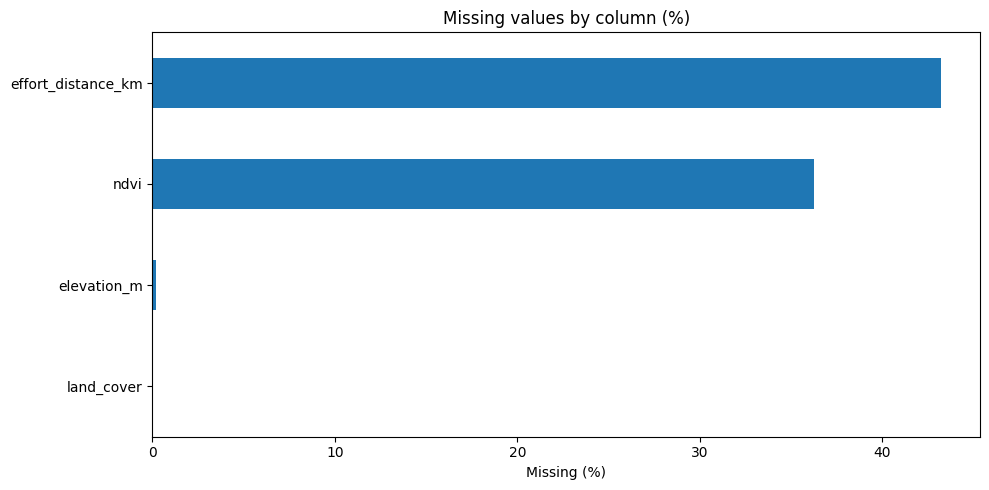

In [ ]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
display(missing)
missing.to_csv(OUTPUT / 'missing_value_report.csv')
plt.figure(figsize=(10, 5))
missing[missing.missing_count > 0]['missing_percent'].sort_values().plot(kind='barh')
plt.title('Missing values by column (%)')
plt.xlabel('Missing (%)')
plt.tight_layout()
plt.show()

### Missing-data decisions
- `target_occurrence`: verified binary labels are already supplied. Never impute Y.
- `cell_id` and survey identifiers: never fill with numeric averages; retain them for validation.
- `elevation_m` and `ndvi`: preserve missingness, then fit median imputation on training folds only.
- `land_cover`: retain source-prefixed classifications. The source changes in 2021;
  encoding does not make the two classifications scientifically equivalent.
- `effort_distance_km`: stationary blanks are not unknown traveling distances.
  Use the verified derived `survey_distance_km` feature, whose stationary value is structurally zero.
- Do not drop every row with an environmental gap or alter Y because an environmental measurement is missing.

## 3. EDA — species, target Y and geographic cells
Counts are checklist–species pairs unless labelled as **surveys**. Because every survey
has one row for each of the 24 species, ordinary species row counts are equal by design.
The graphs therefore compare actual detections (`Y = 1`) and non-detections (`Y = 0`).

### 3.1 Target Y balance
Compare all checklist–species labels. A non-detection is not confirmed biological absence.

,meaning,rows,percent
target_occurrence,,,
0,Y = 0: not detected,451395,89.28
1,Y = 1: detected,54213,10.72


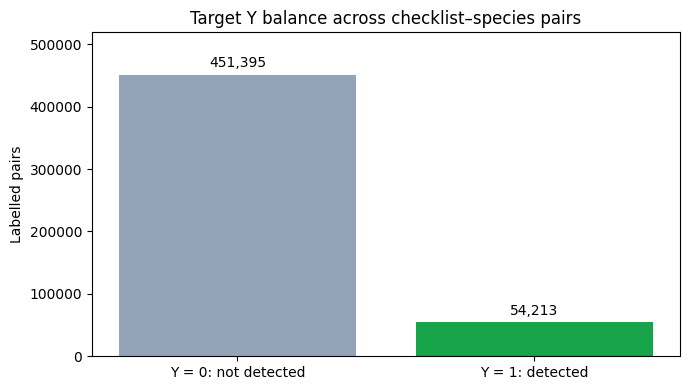

In [ ]:
target_counts = df['target_occurrence'].value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame({
    'meaning': ['Y = 0: not detected', 'Y = 1: detected'],
    'rows': target_counts.to_numpy(),
    'percent': (target_counts.to_numpy() / len(df) * 100).round(2)
}, index=pd.Index([0, 1], name='target_occurrence'))
display(target_summary)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_summary['meaning'], target_summary['rows'], color=['#94a3b8', '#16a34a'])
ax.bar_label(bars, labels=[f'{count:,}' for count in target_summary['rows']], padding=3)
ax.set_title('Target Y balance across checklist–species pairs')
ax.set_ylabel('Labelled pairs')
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

### 3.2 Species and their Y targets
Each species has the same number of surveyed checklists. The two bar segments show
how many of those surveys detected the species and how many did not detect it.

target_occurrence,not_detected_y0,detected_y1,detection_percent
scientific_name,,,
Dinopium psarodes,12191,8876,42.13
Psilopogon rubricapillus,12585,8482,40.26
Loriculus beryllinus,14466,6601,31.33
Psilopogon flavifrons,16824,4243,20.14
Treron pompadora,16916,4151,19.70
Gallus lafayettii,17530,3537,16.79
Ocyceros gingalensis,18097,2970,14.10
Rubigula melanictera,18375,2692,12.78
Psittacula calthrapae,18951,2116,10.04


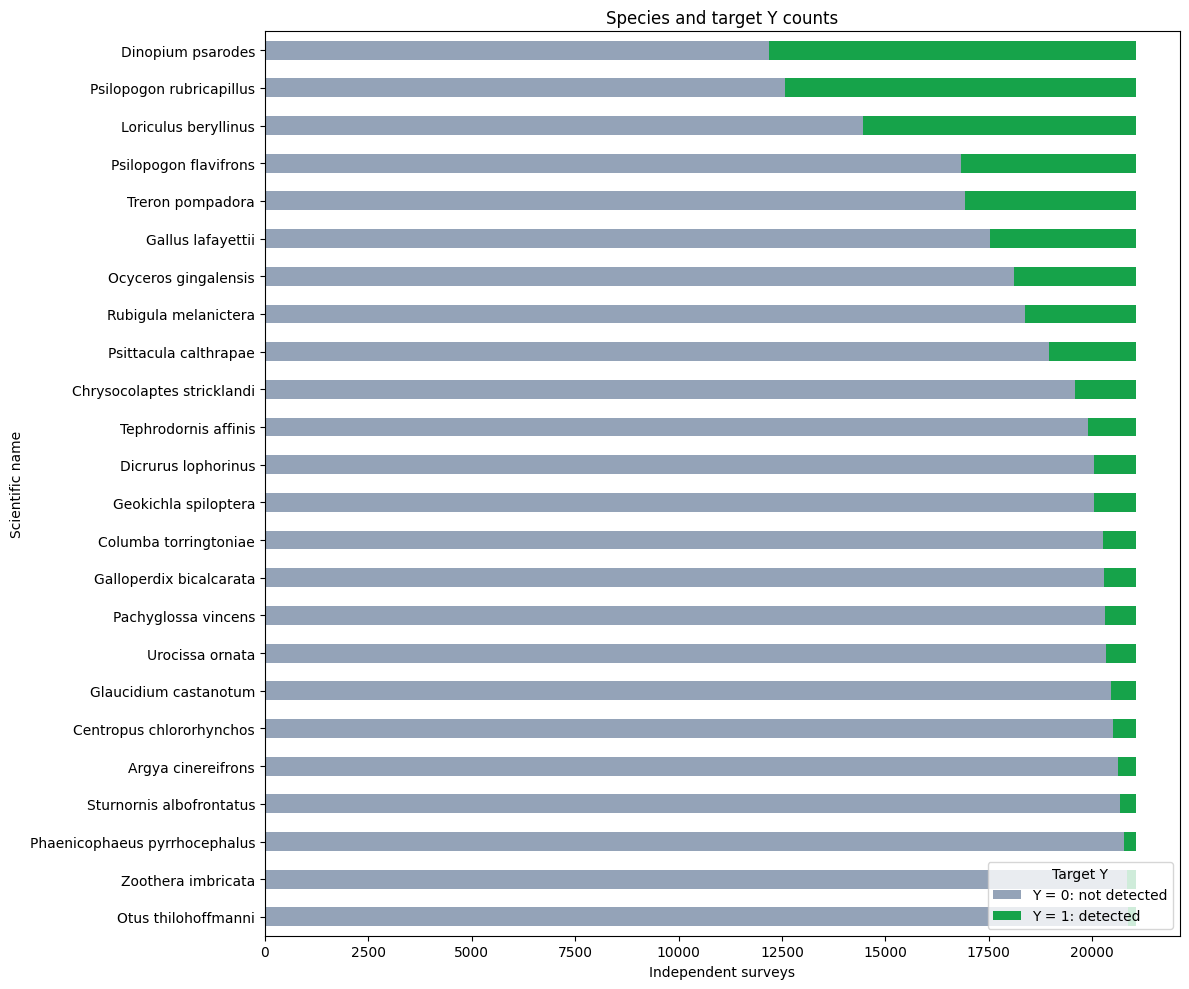

In [ ]:
species_y = pd.crosstab(df['scientific_name'], df['target_occurrence']).reindex(columns=[0, 1], fill_value=0)
species_y = species_y.sort_values(1, ascending=True)
species_summary = species_y.rename(columns={0: 'not_detected_y0', 1: 'detected_y1'}).copy()
species_summary['detection_percent'] = (species_y[1] / species_y.sum(axis=1) * 100).round(2)
display(species_summary.sort_values('detected_y1', ascending=False))
species_summary.to_csv(OUTPUT / 'species_target_summary.csv')
ax = species_y.rename(columns={0: 'Y = 0: not detected', 1: 'Y = 1: detected'}).plot(
    kind='barh', stacked=True, figsize=(12, 10), color=['#94a3b8', '#16a34a']
)
ax.set_title('Species and target Y counts')
ax.set_xlabel('Independent surveys')
ax.set_ylabel('Scientific name')
ax.legend(title='Target Y', loc='lower right')
plt.tight_layout()
plt.show()

### 3.3 Species targets by geographic cell
Show the 20 most-surveyed cells by default; change `TOP_N_CELLS` below.
The heatmap shows the percentage of surveys detecting each species within each cell.
Column labels include the survey count (`n`). This is a detection rate, not occupancy probability.
Unsampled combinations stay missing rather than being shown as zero.

,cell_id,scientific_name,surveys,detected_y1,not_detected_y0,detection_percent
2064,lka_laea_5000m_-12_-41,Argya cinereifrons,830,0,830,0.000000
2065,lka_laea_5000m_-12_-41,Centropus chlororhynchos,830,0,830,0.000000
2066,lka_laea_5000m_-12_-41,Chrysocolaptes stricklandi,830,0,830,0.000000
2067,lka_laea_5000m_-12_-41,Columba torringtoniae,830,0,830,0.000000
2068,lka_laea_5000m_-12_-41,Dicrurus lophorinus,830,0,830,0.000000
2069,lka_laea_5000m_-12_-41,Dinopium psarodes,830,566,264,68.192771
2070,lka_laea_5000m_-12_-41,Galloperdix bicalcarata,830,0,830,0.000000
2071,lka_laea_5000m_-12_-41,Gallus lafayettii,830,0,830,0.000000
2072,lka_laea_5000m_-12_-41,Geokichla spiloptera,830,0,830,0.000000
2073,lka_laea_5000m_-12_-41,Glaucidium castanotum,830,0,830,0.000000


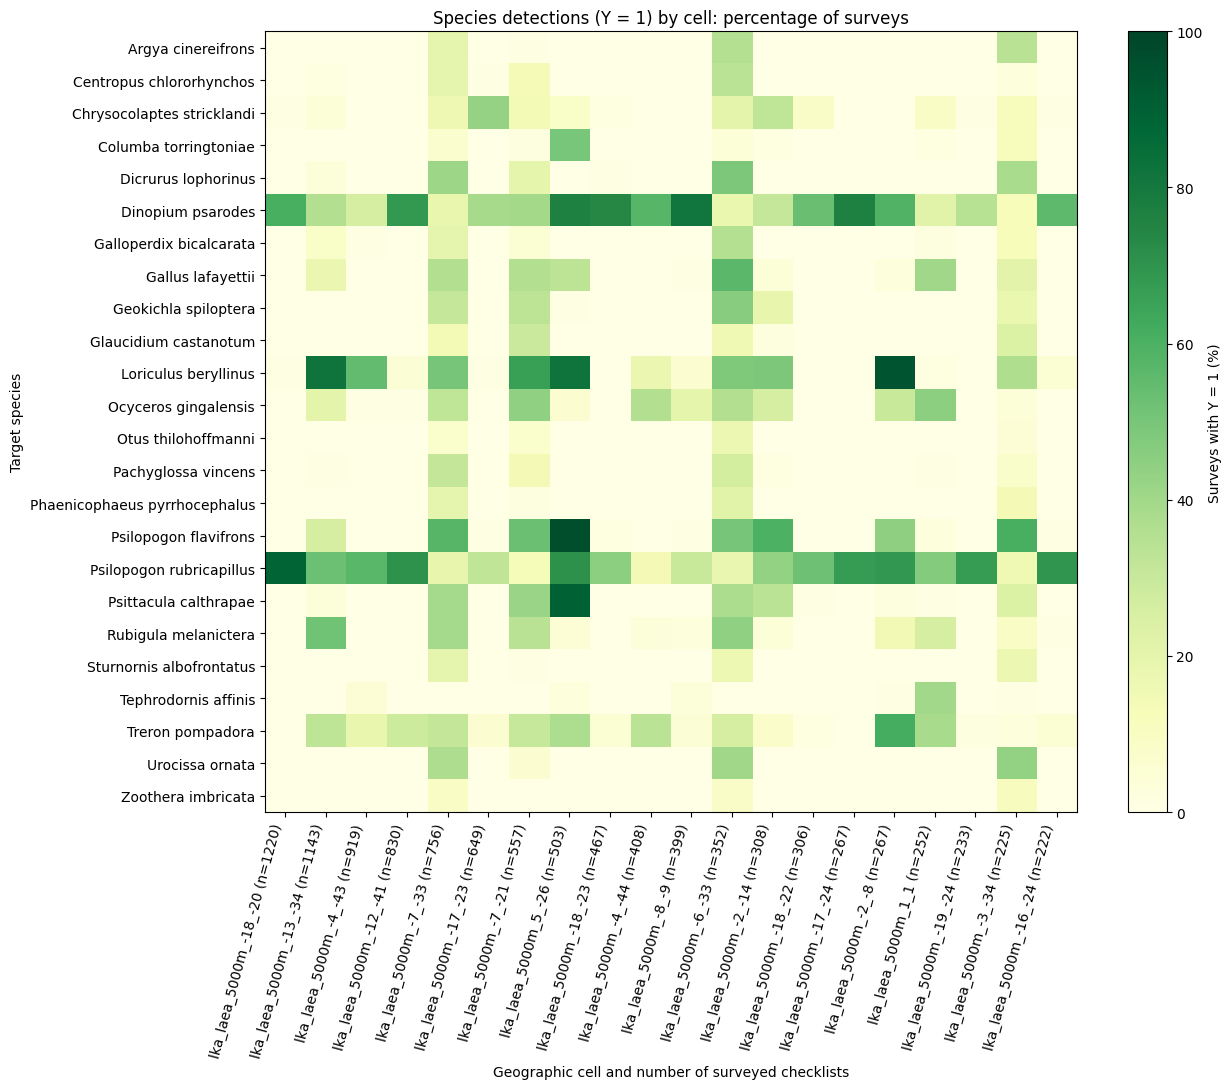

In [ ]:
TOP_N_CELLS = 20
cell_species_summary = (
    df.groupby(['cell_id', 'scientific_name'], observed=True)
      .agg(surveys=('target_occurrence', 'size'), detected_y1=('target_occurrence', 'sum'))
      .reset_index()
)
cell_species_summary['not_detected_y0'] = cell_species_summary['surveys'] - cell_species_summary['detected_y1']
cell_species_summary['detection_percent'] = 100 * cell_species_summary['detected_y1'] / cell_species_summary['surveys']
cell_species_summary.to_csv(OUTPUT / 'cell_species_target_summary.csv', index=False)
cell_survey_counts = survey_df.groupby('cell_id')['checklist_id'].nunique().sort_values(ascending=False)
top_cells = cell_survey_counts.head(TOP_N_CELLS).index.tolist()
cell_heatmap = cell_species_summary.pivot(index='scientific_name', columns='cell_id', values='detection_percent')
cell_heatmap = cell_heatmap.reindex(columns=top_cells).sort_index()
display(cell_species_summary[cell_species_summary['cell_id'].isin(top_cells)].head(24))

if cell_heatmap.empty:
    print('No valid geographic cells are available for plotting.')
else:
    fig, ax = plt.subplots(figsize=(max(12, len(top_cells) * 0.65), 11))
    image = ax.imshow(np.ma.masked_invalid(cell_heatmap.to_numpy()), vmin=0, vmax=100,
                      cmap='YlGn', aspect='auto')
    ax.set_xticks(range(len(top_cells)))
    ax.set_xticklabels([f'{cid} (n={cell_survey_counts[cid]})' for cid in top_cells], rotation=75, ha='right')
    ax.set_yticks(range(len(cell_heatmap.index)))
    ax.set_yticklabels(cell_heatmap.index)
    ax.set_xlabel('Geographic cell and number of surveyed checklists')
    ax.set_ylabel('Target species')
    ax.set_title('Species detections (Y = 1) by cell: percentage of surveys')
    fig.colorbar(image, ax=ax, label='Surveys with Y = 1 (%)')
    plt.tight_layout()
    plt.show()

### 3.4 Inspect Y = 0 and Y = 1 for one cell
Leave `SELECTED_CELL_ID = None` to inspect the most-surveyed cell, or enter a `cell_id`
from the previous graph and run this cell again.

target_occurrence,not_detected_y0,detected_y1
scientific_name,,
Argya cinereifrons,1220,0
Sturnornis albofrontatus,1220,0
Rubigula melanictera,1220,0
Psittacula calthrapae,1220,0
Psilopogon flavifrons,1220,0
Phaenicophaeus pyrrhocephalus,1220,0
Otus thilohoffmanni,1220,0
Urocissa ornata,1220,0
Glaucidium castanotum,1220,0


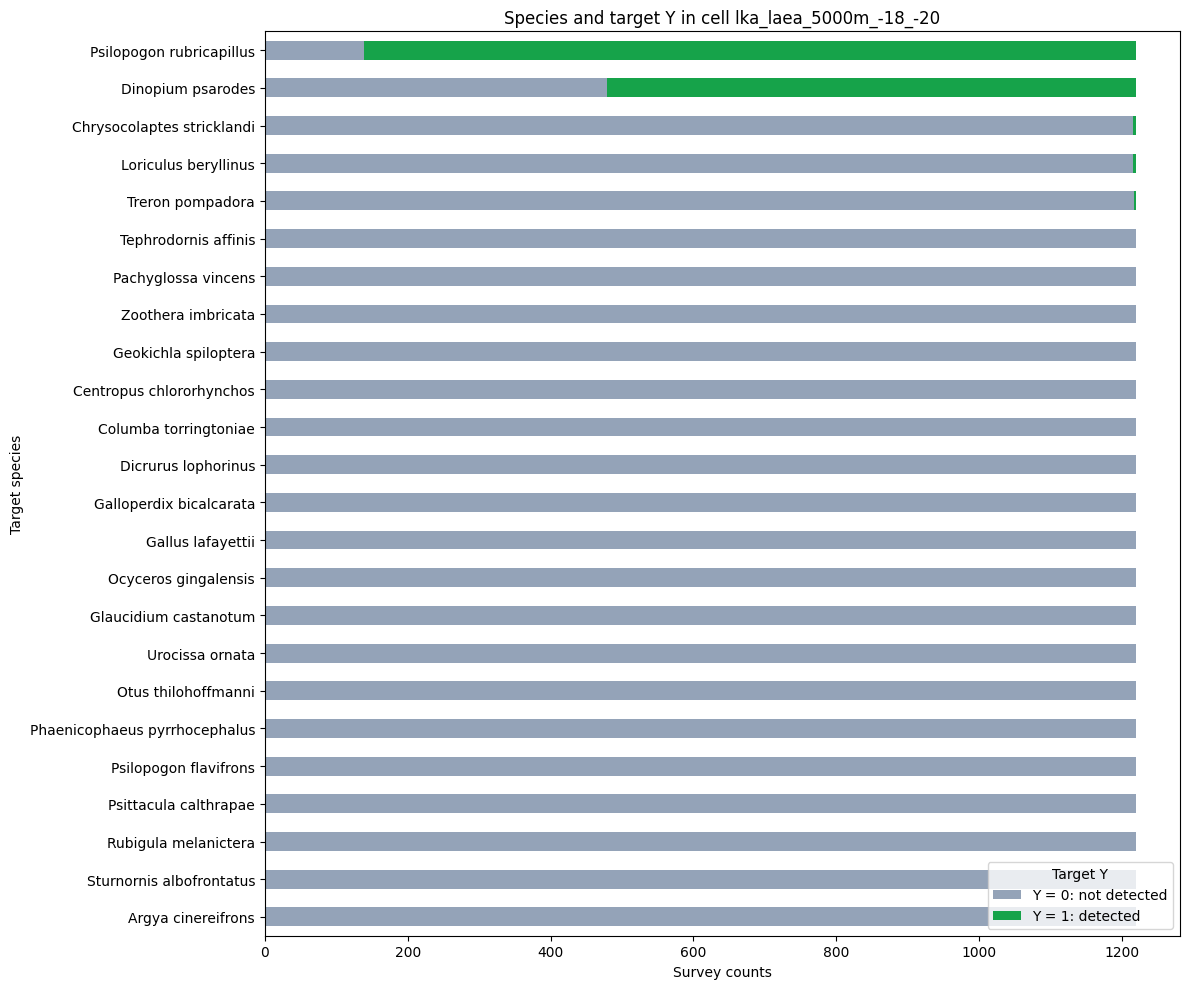

In [ ]:
SELECTED_CELL_ID = None  # Example: replace None with a quoted cell_id from section 3.3.
selected_cell_id = SELECTED_CELL_ID
if selected_cell_id is None and not cell_survey_counts.empty:
    selected_cell_id = cell_survey_counts.index[0]
selected = df[df['cell_id'].eq(selected_cell_id)]
if selected.empty:
    print('No surveys found for cell:', selected_cell_id)
else:
    selected_y = pd.crosstab(selected['scientific_name'], selected['target_occurrence']).reindex(columns=[0, 1], fill_value=0)
    selected_y = selected_y.sort_values(1)
    display(selected_y.rename(columns={0: 'not_detected_y0', 1: 'detected_y1'}))
    ax = selected_y.rename(columns={0: 'Y = 0: not detected', 1: 'Y = 1: detected'}).plot(
        kind='barh', stacked=True, figsize=(12, 10), color=['#94a3b8', '#16a34a']
    )
    ax.set_title(f'Species and target Y in cell {selected_cell_id}')
    ax.set_xlabel('Survey counts')
    ax.set_ylabel('Target species')
    ax.legend(title='Target Y', loc='lower right')
    plt.tight_layout()
    plt.show()

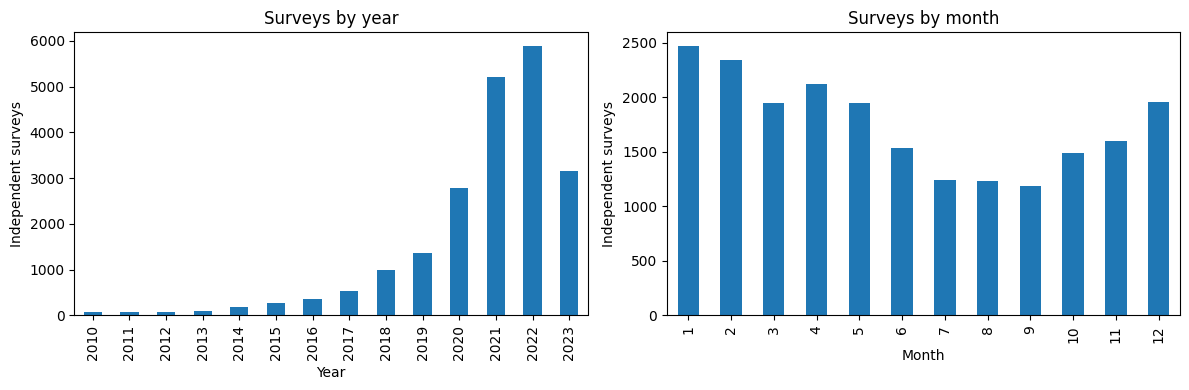

In [ ]:
# Count each survey once when examining sampling by year and month.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
survey_df['year'].value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Surveys by year')
survey_df['month'].value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Surveys by month')
ax[0].set_xlabel('Year')
ax[1].set_xlabel('Month')
for axis in ax:
    axis.set_ylabel('Independent surveys')
plt.tight_layout()
plt.show()

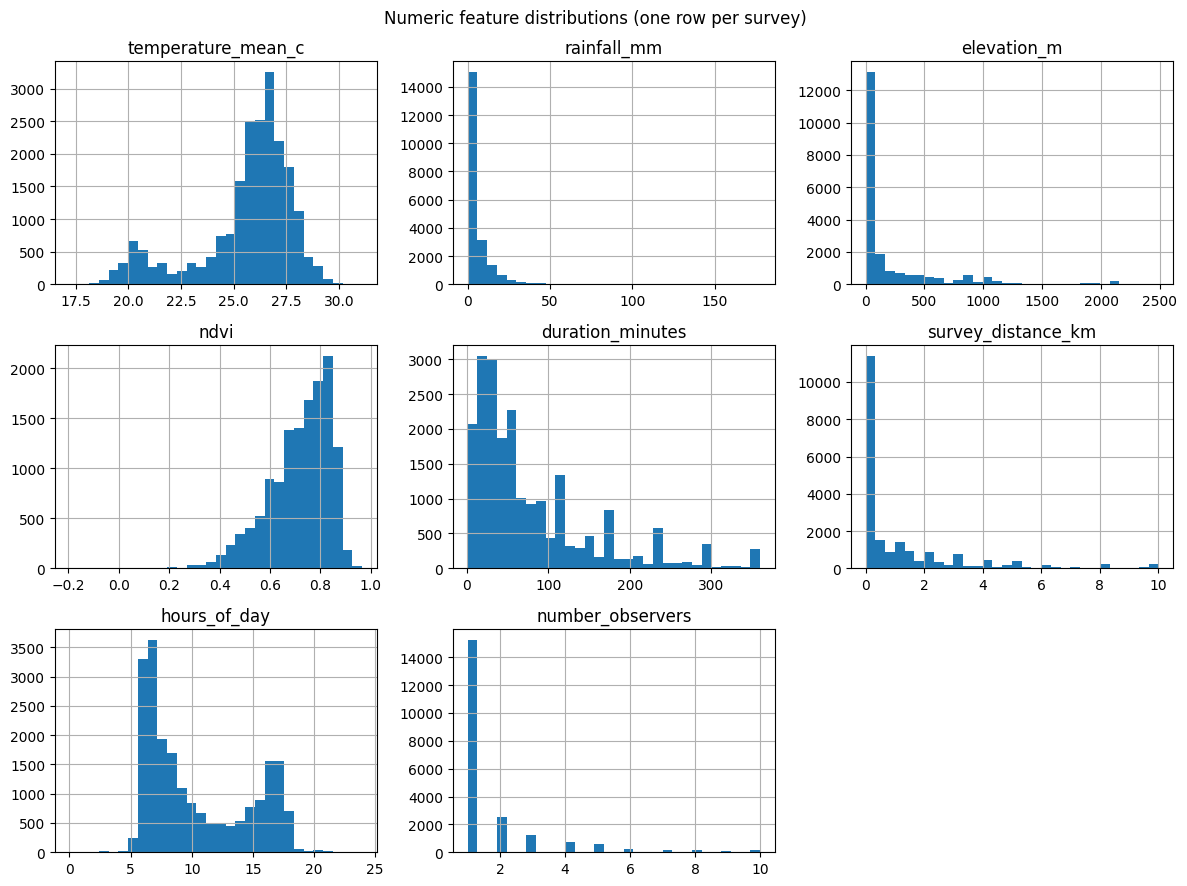

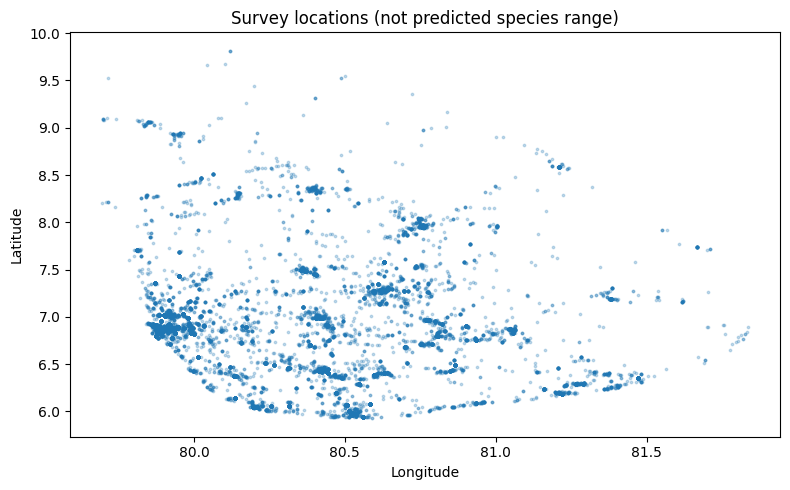

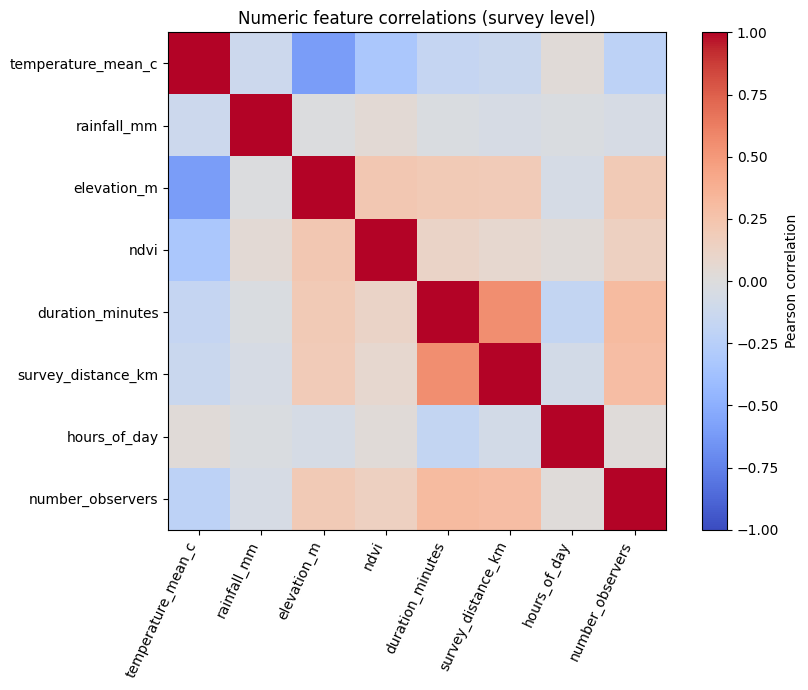

In [ ]:
numeric = ['temperature_mean_c', 'rainfall_mm', 'elevation_m', 'ndvi',
           'duration_minutes', 'survey_distance_km', 'hours_of_day', 'number_observers']
survey_df[numeric].hist(figsize=(12, 9), bins=30)
plt.suptitle('Numeric feature distributions (one row per survey)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(survey_df['longitude'], survey_df['latitude'], s=3, alpha=0.25)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Survey locations (not predicted species range)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
plt.imshow(survey_df[numeric].corr(), vmin=-1, vmax=1, cmap='coolwarm')
plt.xticks(range(len(numeric)), numeric, rotation=65, ha='right')
plt.yticks(range(len(numeric)), numeric)
plt.colorbar(label='Pearson correlation')
plt.title('Numeric feature correlations (survey level)')
plt.tight_layout()
plt.show()

## 4. Data cleaning and quality checks
The unique row key is **(`checklist_id`, `scientific_name`)**. There is no observation-level
`record_id` in this training table, since non-detections are derived survey–species rows.
Different species from the same survey must not be removed as duplicates. Preserve Y and
its audit status while checking dates, coordinates and environmental ranges.

In [ ]:
clean = df.copy()
clean['observation_date'] = pd.to_datetime(clean['observation_date'], errors='coerce')
print('Exact duplicate rows:', clean.duplicated().sum())
print('Repeated checklist/species keys:', clean.duplicated(['checklist_id', 'scientific_name']).sum())
print('Missing parsed dates:', clean['observation_date'].isna().sum())

clean['invalid_coordinates'] = (~clean['latitude'].between(-90, 90) |
                                ~clean['longitude'].between(-180, 180) |
                                clean[['latitude', 'longitude']].isna().any(axis=1))
clean['invalid_month'] = ~clean['month'].between(1, 12)
clean['date_mismatch'] = (clean['observation_date'].notna() &
    ((clean['observation_date'].dt.year != clean['year']) |
     (clean['observation_date'].dt.month != clean['month'])))
clean['invalid_ndvi'] = clean['ndvi'].notna() & ~clean['ndvi'].between(-0.2, 1)
clean['invalid_rainfall'] = clean['rainfall_mm'].notna() & (clean['rainfall_mm'] < 0)
clean['invalid_duration'] = clean['duration_minutes'].isna() | ~clean['duration_minutes'].between(0, 360, inclusive='right')
clean['invalid_distance'] = clean['survey_distance_km'].isna() | ~clean['survey_distance_km'].between(0, 10)
clean['invalid_target'] = clean['target_occurrence'].isna() | ~clean['target_occurrence'].isin([0, 1])
flags = [c for c in clean.columns if c.startswith('invalid_') or c == 'date_mismatch']
print('\nQuality checks:')
print(clean[flags].sum())

clean = clean.drop_duplicates().copy()
if clean.duplicated(['checklist_id', 'scientific_name']).any():
    raise ValueError('Conflicting checklist/species rows need review; they must not be silently removed.')
if clean['invalid_target'].any():
    raise ValueError('Invalid target values need review; do not impute them.')
if clean.groupby('survey_group_id')['checklist_id'].nunique().gt(1).any():
    raise ValueError('Multiple checklists represent the same shared survey; review before modelling.')
print('Rows after exact duplicate removal:', len(clean))

Exact duplicate rows: 0
Repeated checklist/species keys: 0
Missing parsed dates: 0

Quality checks:
invalid_coordinates    0
invalid_month          0
date_mismatch          0
invalid_ndvi           0
invalid_rainfall       0
invalid_duration       0
invalid_distance       0
invalid_target         0
dtype: int64
Rows after exact duplicate removal: 505608


## 5. Missingness by year and protocol
Check whether environmental gaps depend on year or protocol. Missing original stationary
distance is distinguished from the usable derived `survey_distance_km` feature.

In [ ]:
display((clean.groupby('year')[['ndvi', 'duration_minutes', 'effort_distance_km']]
         .apply(lambda x: x.isna().mean().mul(100).round(1))))
display(clean.groupby('protocol')[['duration_minutes', 'effort_distance_km']]
        .apply(lambda x: x.isna().mean().mul(100).round(1)))
print('Land-cover values:')
print(clean['land_cover'].value_counts(dropna=False).head(30))

,ndvi,duration_minutes,effort_distance_km
year,,,
2010,31.7,0.0,3.7
2011,25.4,0.0,14.1
2012,18.3,0.0,15.5
2013,20.2,0.0,18.3
2014,19.3,0.0,18.8
2015,22.0,0.0,22.3
2016,23.0,0.0,22.0
2017,14.8,0.0,20.3
2018,23.8,0.0,31.1


,duration_minutes,effort_distance_km
protocol,,
Stationary,0.0,100.0
Traveling,0.0,0.0


Land-cover values:
land_cover
ESRI_7         158304
ESRI_2         129816
ESA_CCI_190     47016
ESA_CCI_50      41592
ESRI_5          27768
ESA_CCI_100     17352
ESA_CCI_121     16392
ESRI_1          15048
ESA_CCI_30      14592
ESRI_11          9168
ESA_CCI_10       7872
ESA_CCI_210      4680
ESA_CCI_40       4680
ESA_CCI_20       4248
ESA_CCI_11       2952
ESA_CCI_70       1656
ESRI_4           1272
ESA_CCI_120       792
ESRI_8            144
ESA_CCI_60         96
NaN                48
ESA_CCI_170        48
ESA_CCI_61         24
ESA_CCI_200        24
ESA_CCI_130        24
Name: count, dtype: int64
